# 03. 최종 결론 — KRX 전처리는 정말 필요한가?

**한 줄 결론**: 본 데이터는 **KRX 원자료 + 우리가 보정한 `krx_adjusted.parquet`** 를 쓰고, 네이버·야후는 검증용 *보조*로만 쓴다.

아래 질문에 숫자로 답하면서 확인한다.
1. 네이버나 야후만 쓰면 무엇이 빠지나?
2. 보정을 안 하면 실제로 얼마나 틀리나?
3. 보정은 얼마나 정확한가? (남은 한계)
4. 그래서 어떻게 쓸까?

(예전 09번 노트북을 고친 것이다. 예전 것은 맨 앞에 길 찾기 칸이 없어서 `indexbeater` 를 찾지 못하는 오류가 났다.)

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
# (예전 07~09번 노트북은 이 칸이 없어서 "indexbeater 를 찾을 수 없다"는 오류가 났다.)
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from indexbeater.krx_source import paths, external

# 그래프의 한글이 네모(□)로 깨지지 않게 윈도우 기본 한글 글꼴을 쓴다.
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False      # 마이너스(-) 기호가 깨지는 것도 막는다
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # 표의 소수점은 네 자리까지만

raw = pd.read_parquet(paths.RAW_DAILY, columns=["date", "market", "code", "close"])
adj = pd.read_parquet(paths.ADJUSTED, columns=["date", "market", "code", "adj_close"])
last = raw.groupby("code")["date"].max()
alive = last >= raw["date"].max() - pd.Timedelta(days=7)       # 마지막 주에도 거래가 있으면 '살아있음'
info = raw.groupby("code")["market"].first().to_frame(); info["살아있음"] = alive
print("준비 완료:", len(info), "종목 (ETF 포함)")

준비 완료: 4982 종목 (ETF 포함)


## 1. 네이버·야후만 쓰면 무엇이 빠지나 (생존편향·범위)

,출처,주식_종목수,ETF,상장폐지_주식
0,KRX(원자료),3527,1455,755
1,네이버,3526,0,755
2,새 야후,2764,0,0


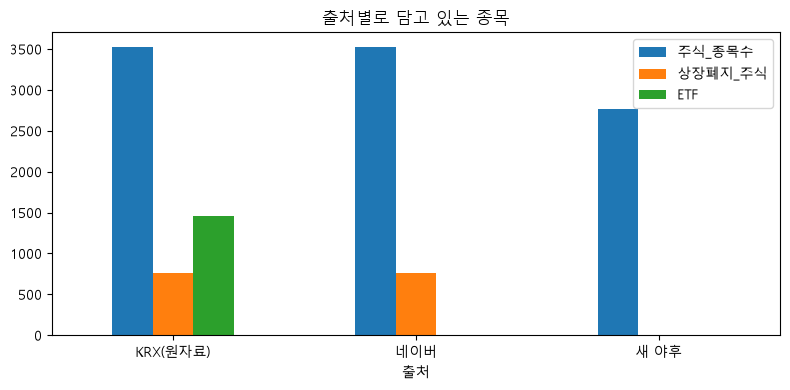

In [3]:
ycodes = set(external.yf_index())
ncodes = {p.stem for p in paths.NAVER_DIR.glob("*.csv")}         # 네이버 파일 이름 = 종목코드.csv
rows = []
for name, s in [("KRX(원자료)", set(info.index)), ("네이버", ncodes), ("새 야후", ycodes)]:
    sub = info[info.index.isin(s)]
    rows.append(dict(출처=name, 주식_종목수=int((sub["market"] != "ETF").sum()), ETF=int((sub["market"] == "ETF").sum()),
                     상장폐지_주식=int(((sub["market"] != "ETF") & (~sub["살아있음"])).sum())))
cv = pd.DataFrame(rows); display(cv)
ax = cv.set_index("출처")[["주식_종목수", "상장폐지_주식", "ETF"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_title("출처별로 담고 있는 종목"); plt.tight_layout(); plt.show()

**읽는 법**: 야후는 상장폐지 종목이 거의 **0개**다. 네이버는 폐지 종목은 있지만 **ETF·시가총액·거래대금·배당**이 없다.
우리 목표(KOSPI200/KOSDAQ150 ETF를 이기는 신호)에는 ① 폐지 종목 포함 ② 시가총액·거래대금으로 대상 종목 고르기 ③ 배당 포함 수익률이 필요하다. 세 가지를 모두 가진 것은 KRX 원자료뿐이다.

### 생존편향이란? (쉬운 예)
**달리기 대회**: 10년 전에 100명이 마라톤을 시작했다. 지금 *결승선에 서 있는 사람*만 불러서 평균 기록을 물으면 당연히 좋게 나온다. 중간에 포기한 사람은 명단에서 사라졌으니까.
**주식도 같다**: 야후처럼 *지금 살아있는 종목*만으로 "10년 전에 전 종목을 샀다면?"을 계산하면, 망해서 사라진 종목이 빠져 **수익이 실제보다 좋게** 나온다.

아래는 2015년 첫 거래일에 상장돼 있던 일반 주식을 똑같은 금액씩 샀다고 보고, ① 폐지 종목까지 포함 ② 지금 살아있는 종목만(야후 방식) 두 가지로 계산한 것이다. (단순화: 폐지 종목은 마지막 가격이 그대로 유지된다고 본다.)

시작일 종목 수 1964 / 이후 폐지 345개 (18%)
폐지 종목의 최종 배수 중앙값 0.24 (1이면 본전, 1보다 작으면 손실)
최종 자산 배수: 폐지 포함(정답) 1.84배 / 생존만(야후식) 1.97배
연 수익률: 폐지 포함(정답) 5.3% / 생존만 5.9%


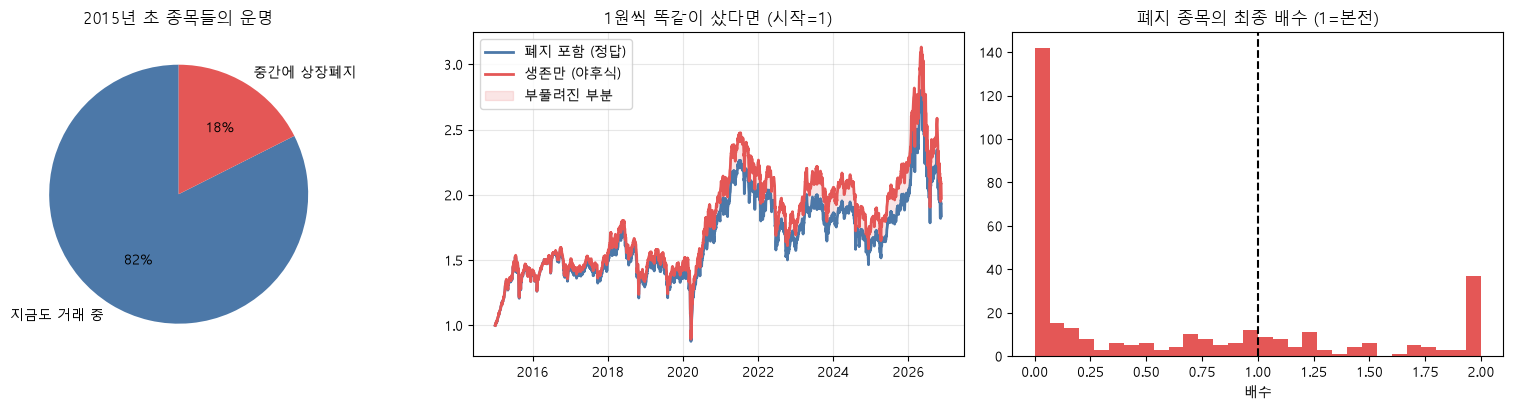

In [4]:
s = adj[adj["market"] != "ETF"][["date", "code", "adj_close"]]
px = s.pivot(index="date", columns="code", values="adj_close").sort_index()
px = px[px.index >= "2015-01-02"]
p0 = px.iloc[0]; use = p0.dropna().index                 # 시작일에 거래되던 종목
rel = (px[use] / p0[use]).ffill()                         # 시작가 = 1. 폐지 후에는 마지막 값 유지
alive_end = px[use].iloc[-1].notna()                      # 마지막 날에도 살아있는 종목
all_curve = rel.mean(axis=1)                              # 폐지 포함 (정답)
surv_curve = rel.loc[:, alive_end].mean(axis=1)           # 살아남은 종목만 (야후 방식)
dead_final = rel.loc[:, ~alive_end].iloc[-1]
yrs = (px.index[-1] - px.index[0]).days / 365.25
print(f"시작일 종목 수 {len(use)} / 이후 폐지 {int((~alive_end).sum())}개 ({(~alive_end).mean():.0%})")
print(f"폐지 종목의 최종 배수 중앙값 {dead_final.median():.2f} (1이면 본전, 1보다 작으면 손실)")
print(f"최종 자산 배수: 폐지 포함(정답) {all_curve.iloc[-1]:.2f}배 / 생존만(야후식) {surv_curve.iloc[-1]:.2f}배")
print(f"연 수익률: 폐지 포함(정답) {all_curve.iloc[-1] ** (1 / yrs) - 1:.1%} / 생존만 {surv_curve.iloc[-1] ** (1 / yrs) - 1:.1%}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cnt = pd.Series({"지금도 거래 중": int(alive_end.sum()), "중간에 상장폐지": int((~alive_end).sum())})
ax[0].pie(cnt, labels=cnt.index, autopct="%1.0f%%", startangle=90, colors=["#4C78A8", "#E45756"]); ax[0].set_title("2015년 초 종목들의 운명")
ax[1].plot(all_curve.index, all_curve, label="폐지 포함 (정답)", color="#4C78A8", lw=2)
ax[1].plot(surv_curve.index, surv_curve, label="생존만 (야후식)", color="#E45756", lw=2)
ax[1].fill_between(all_curve.index, all_curve, surv_curve, color="#E45756", alpha=.15, label="부풀려진 부분")
ax[1].set_title("1원씩 똑같이 샀다면 (시작=1)"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].hist(dead_final.clip(0, 2), bins=30, color="#E45756"); ax[2].axvline(1, color="k", ls="--")
ax[2].set_title("폐지 종목의 최종 배수 (1=본전)"); ax[2].set_xlabel("배수")
plt.tight_layout(); plt.show()
del px, rel

**그림 읽는 법**
- 왼쪽: 2015년 초에 있던 종목 중 일부는 이후 사라졌다. 이 종목들은 야후에 **아예 없다**.
- 가운데: 빨간선(생존만)이 파란선(전체)보다 위에 있다. 두 선 사이가 **생존편향이 만든 가짜 수익**이다.
- 오른쪽: 사라진 종목은 대부분 1(본전) 아래, 즉 손실로 끝났다.

## 2. 보정을 안 하면 얼마나 틀리나

,원자료 그대로,우리 보정 후
하루 등락 31% 초과 횟수,3139,1103


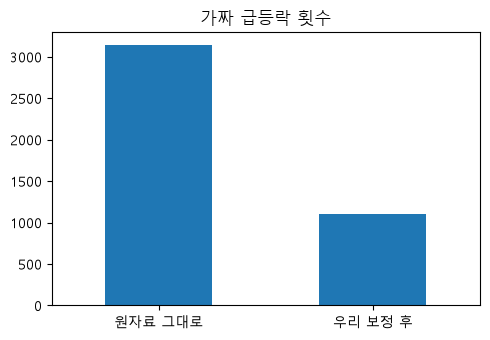

In [5]:
r0 = raw[raw["market"] != "ETF"].sort_values(["code", "date"])
a0 = adj[adj["market"] != "ETF"].sort_values(["code", "date"])
th = 0.31
t = pd.DataFrame({"원자료 그대로": [int((r0.groupby("code")["close"].pct_change().abs() > th).sum())],
                  "우리 보정 후": [int((a0.groupby("code")["adj_close"].pct_change().abs() > th).sum())]},
                 index=["하루 등락 31% 초과 횟수"])
display(t)
ax = t.T.plot.bar(legend=False, figsize=(5, 3.5), rot=0); ax.set_title("가짜 급등락 횟수"); plt.tight_layout(); plt.show()
del r0, a0

원자료의 큰 변동은 대부분 액면분할·병합·권리락 같은 **회계상 사건**이지 진짜 가격 움직임이 아니다. 이대로 신호를 만들면 "하루 -50% 후 반등" 같은 가짜 패턴을 배운다. 보정 후 남은 것은 대부분 거래정지 뒤 재개 같은 **실제 움직임**이다(01번 노트북 3절: 네이버에도 똑같이 있음).

보정을 빼면 연 수익률이 낮게 나오는 정도(%p): 평균 0.66 / 중앙값 0.68 / 상위 10% 3.59


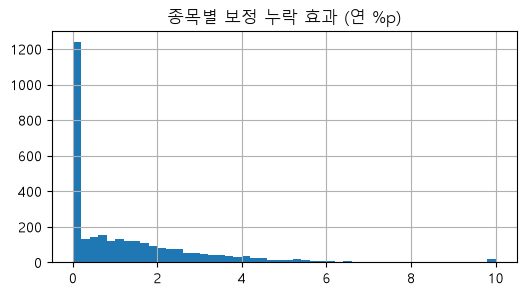

In [6]:
# 배당 효과: 분할만 보정한 가격(배당 없음)과 최종 가격(배당 포함)의 연 수익률 차이를 종목별로 잰다.
b = pd.read_parquet(paths.ADJUSTED_SPLIT_ONLY, columns=["date", "code", "market", "close_s"])
m = adj.merge(b, on=["date", "code", "market"])
m = m[m["market"] != "ETF"].sort_values(["code", "date"])
g = m.groupby("code")
res = pd.DataFrame({"with": g["adj_close"].last() / g["adj_close"].first(), "without": g["close_s"].last() / g["close_s"].first()})
yrs_c = (g["date"].max() - g["date"].min()).dt.days / 365.25
res = res[yrs_c >= 2]; yrs_c = yrs_c[res.index]
res["gap"] = (res["with"] ** (1 / yrs_c) - res["without"] ** (1 / yrs_c)) * 100
print(f"보정을 빼면 연 수익률이 낮게 나오는 정도(%p): 평균 {res['gap'].mean():.2f} / 중앙값 {res['gap'].median():.2f} / 상위 10% {res['gap'].quantile(.9):.2f}")
res["gap"].clip(0, 10).hist(bins=50, figsize=(6, 3)); plt.title("종목별 보정 누락 효과 (연 %p)"); plt.show()
del b, m

**읽는 법**: 분할만 보정한 가격과 최종 가격의 차이는 대부분 **배당**에서 온다(유상증자·기준가 보정도 조금 섞여 있다). 이 차이를 빼먹으면 배당을 많이 주는 종목일수록 수익률이 낮게 잡힌다.

## 3. 보정은 얼마나 정확한가 — 남은 한계 (숨기지 않는다)

네이버와 우리 가격을 종목별로 비교한 결과가 `data/krx_quality_flags.csv` 에 있다. 일치율 90% 미만이면 `의심` 표시다.
(주의: 이 파일을 만드는 코드는 아직 패키지에 없다. 만들 때의 계산을 `krx_source` 명령으로 옮기는 것이 남은 일이다.)

In [7]:
from indexbeater.config import KRX_QUALITY_FLAGS
q = pd.read_csv(KRX_QUALITY_FLAGS, dtype={"code": str})
print(q["flag"].value_counts().to_string())
t = q.groupby("flag")["avg_value"].sum()
display((t / t.sum()).round(3).rename("거래대금 비중"))
for k in (300, 1000):
    print("거래대금 상위", k, "종목:", q.nlargest(k, "avg_value")["flag"].value_counts().to_dict())

flag
양호                      2743
의심(네이버와 90퍼센트 미만 일치)     755
네이버없음                     29


flag
네이버없음                  0.0940
양호                     0.6610
의심(네이버와 90퍼센트 미만 일치)   0.2450
Name: 거래대금 비중, dtype: float64

거래대금 상위 300 종목: {'양호': 188, '의심(네이버와 90퍼센트 미만 일치)': 94, '네이버없음': 18}
거래대금 상위 1000 종목: {'양호': 728, '의심(네이버와 90퍼센트 미만 일치)': 253, '네이버없음': 19}


**정직한 해석**
- 대부분 종목(거래대금으로도 대부분)은 네이버와 90% 이상 일치한다 → 믿고 쓴다.
- `의심` 종목은 일치율이 낮다. 이 중 상당수는 **네이버가 틀렸을 수도** 있다(야후까지 셋을 비교하면 '네이버·야후 모두와 불일치'는 약 12%에 그쳤다). 하지만 우리 보정이 틀렸을 가능성도 배제하지 못한다.
- `네이버없음` 은 비교할 수 없는 종목(주로 폐지·특수 종목)이다.
- 그래서 **백테스트는 의심 종목을 뺐을 때와 넣었을 때 결과가 같은지** 반드시 함께 확인한다(민감도 점검).

## 4. 결론 — 무엇을 어떻게 쓰나

| 용도 | 쓸 데이터 | 이유 |
|---|---|---|
| 본 가격·수익률 | **`krx_adjusted.parquet`** 의 `adj_close` (분할+배당+유상+기준가 보정) | 폐지 종목 포함, 배당 포함, 가짜 급등락 제거 |
| 대상 종목 고르기(시총·거래대금) | KRX `mktcap`, `value` | 네이버·야후에는 없음 |
| 비교 기준(벤치마크) | KOSPI200/KOSDAQ150 **ETF** (KRX ETF 가격) | 지수 자체가 아니라 ETF로만 비교하기로 한 규칙 |
| 가격 검증 | 네이버(분할·기준가, 2026-09-13까지) + 새 야후(Adj Close, 배당) | 서로 독립된 출처라 교차검증용 |
| 쓰지 말 것 | 야후 단독 | 상장폐지 종목이 없어 생존편향 |

**KRX 전처리는 꼭 필요한가? 필요하다.** 근거는 위 숫자들이다: (1) 원자료에는 가짜 급등락이 수천 건, (2) 보정을 빼면 연 수익률이 과소평가(위 2절), (3) 폐지 종목을 빼면 결과가 부풀려짐(위 1절), (4) ETF·시가총액·거래대금은 KRX에만 있다.

**다만 완벽하지는 않다**: 의심 종목은 민감도 점검으로 관리하고, 기준가 이벤트의 거래량은 보정하지 않았다(유동성은 거래대금 `value` 로 본다).